# DAV Practical Mini Project: E-Commerce Sales and Customer Behavior Analytics
**Group Members:** Soham Admane, Vaishnav Balpande, Lokesh Parate  
**Course:** Data Analysis and Visualization (DAV) Lab  
**Problem Statement:** Analyze revenue, product categories, customer locations, delivery times, reviews and purchasing trends using Python, Pandas, Plotly, Matplotlib, Seaborn, and Streamlit.


In [2]:
# Step 1: Import Required Libraries
# (Strictly using libraries covered in DAV Practicals 1-8)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

# Apply DAV Practical 7 styling
sns.set_theme(style="whitegrid")
np.random.seed(42)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Section 1: Data Ingestion and Structural Overview (DAV Practical 1 & 2 Style)
Loading the converted CSV dataset and inspecting metadata, columns, and data types.

In [3]:
df = pd.read_csv('ecommerce_sample.csv')
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print('Shape of Dataset:', df.shape)
df.head()

Shape of Dataset: (100000, 24)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year_Sheet,Is_Cancelled,...,Year_Month,DayOfWeek,Hour,Date,Product_Category,Delivery_Days,Delivery_Status,Review_Rating,Review_Category,Customer_Segment
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,False,...,2009-12,Tuesday,7,2009-12-01,Home & Living,3,On-Time,4,Good,At Risk Customers
1,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom,Year 2009-2010,False,...,2009-12,Tuesday,7,2009-12-01,Home & Living,4,Slight Delay,5,Excellent,At Risk Customers
2,489436,21754,HOME BUILDING BLOCK WORD,3,2009-12-01 09:06:00,5.95,13078.0,United Kingdom,Year 2009-2010,False,...,2009-12,Tuesday,9,2009-12-01,Other General Retail,2,On-Time,5,Excellent,Champions
3,489437,21912,VINTAGE SNAKES & LADDERS,4,2009-12-01 09:08:00,3.75,15362.0,United Kingdom,Year 2009-2010,False,...,2009-12,Tuesday,9,2009-12-01,Other General Retail,3,On-Time,4,Good,Hibernating / Inactive
4,489437,22143,CHRISTMAS CRAFT HEART DECORATIONS,6,2009-12-01 09:08:00,2.10,15362.0,United Kingdom,Year 2009-2010,False,...,2009-12,Tuesday,9,2009-12-01,Home & Living,4,Slight Delay,4,Good,Hibernating / Inactive


In [4]:
print('Dataset Summary Info:')
df.info()
print('\nMissing Values Count:')
print(df.isnull().sum())
print('\nStatistical Description:')
df.describe()

Dataset Summary Info:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 24 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Invoice           100000 non-null  str           
 1   StockCode         100000 non-null  str           
 2   Description       100000 non-null  str           
 3   Quantity          100000 non-null  int64         
 4   InvoiceDate       100000 non-null  datetime64[us]
 5   Price             100000 non-null  float64       
 6   Customer ID       77790 non-null   float64       
 7   Country           100000 non-null  str           
 8   Year_Sheet        100000 non-null  str           
 9   Is_Cancelled      100000 non-null  bool          
 10  Total_Amount      100000 non-null  float64       
 11  Year              100000 non-null  int64         
 12  Month             100000 non-null  int64         
 13  Month_Name        100000 non-null  str           

,Quantity,InvoiceDate,Price,Customer ID,Total_Amount,Year,Month,Hour,Delivery_Days,Review_Rating
count,100000.000000,100000,100000.000000,77790.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000
mean,10.113130,2011-01-02 18:22:06.679200,4.730458,15319.560368,18.473351,2010.427380,7.469830,13.02455,3.256440,4.271900
min,-9360.000000,2009-12-01 07:45:00,0.001000,12346.000000,-17836.460000,2009.000000,1.000000,6.00000,0.000000,1.000000
25%,1.000000,2010-07-08 12:09:30,1.250000,13969.000000,3.750000,2010.000000,4.000000,11.00000,2.000000,4.000000
50%,3.000000,2010-12-07 15:39:00,2.100000,15242.000000,9.900000,2010.000000,8.000000,13.00000,3.000000,5.000000
75%,10.000000,2011-07-21 14:52:00,4.150000,16797.000000,17.700000,2011.000000,11.000000,15.00000,4.000000,5.000000
max,7008.000000,2011-12-09 12:50:00,17836.460000,18287.000000,8925.000000,2011.000000,12.000000,20.00000,15.000000,5.000000
std,66.949599,NaN,85.176865,1700.599003,110.526817,0.573663,3.530577,2.43837,1.535748,0.912162


## Section 2: Revenue Analytics (DAV Practical 7 & 8 Style)
Analyzing gross sales, monthly trend with peak annotation, and revenue distribution.

Total Gross Revenue: £1,961,099.67
Total Orders: 27,256
Average Order Value: £71.95


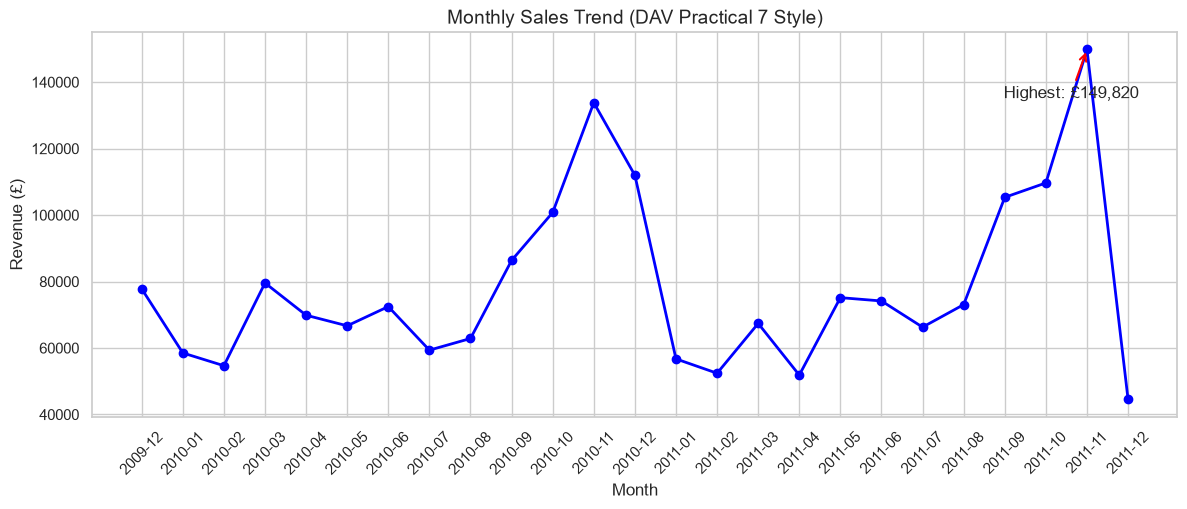

In [5]:
valid_sales = df[~df['Is_Cancelled']]
total_revenue = valid_sales['Total_Amount'].sum()
total_orders = valid_sales['Invoice'].nunique()
print(f'Total Gross Revenue: £{total_revenue:,.2f}')
print(f'Total Orders: {total_orders:,}')
print(f'Average Order Value: £{total_revenue / total_orders:.2f}')

# Monthly Sales Trend with Peak Highlighted (DAV Practical 7 style)
monthly = valid_sales.groupby('Year_Month')['Total_Amount'].sum().reset_index()
max_val = monthly['Total_Amount'].max()
max_m = monthly.loc[monthly['Total_Amount'].idxmax(), 'Year_Month']

plt.figure(figsize=(14, 5))
plt.plot(monthly['Year_Month'], monthly['Total_Amount'], marker='o', color='blue', linewidth=2)
plt.annotate(
    f'Highest: £{max_val:,.0f}',
    xy=(max_m, max_val),
    xytext=(-60, -35),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->', color='red', lw=1.5)
)
plt.title('Monthly Sales Trend (DAV Practical 7 Style)', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

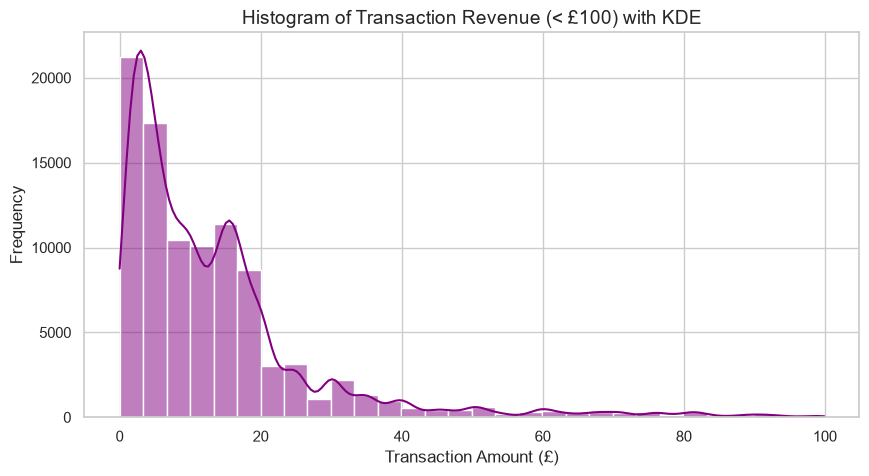

In [6]:
# Histogram with KDE of Transaction Revenue (DAV Practical 8 Style)
plt.figure(figsize=(10, 5))
sns.histplot(valid_sales[valid_sales['Total_Amount'] < 100]['Total_Amount'], bins=30, kde=True, color='purple')
plt.title('Histogram of Transaction Revenue (< £100) with KDE', fontsize=14)
plt.xlabel('Transaction Amount (£)')
plt.ylabel('Frequency')
plt.show()

## Section 3: Product Category Analytics (DAV Practical 8 Style)
Categorization via `np.select`, bar charts, and donut chart.

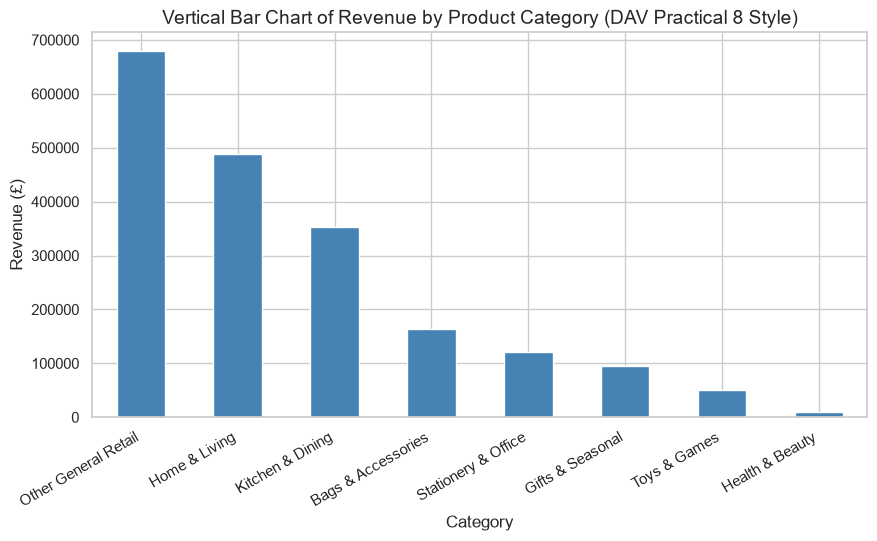

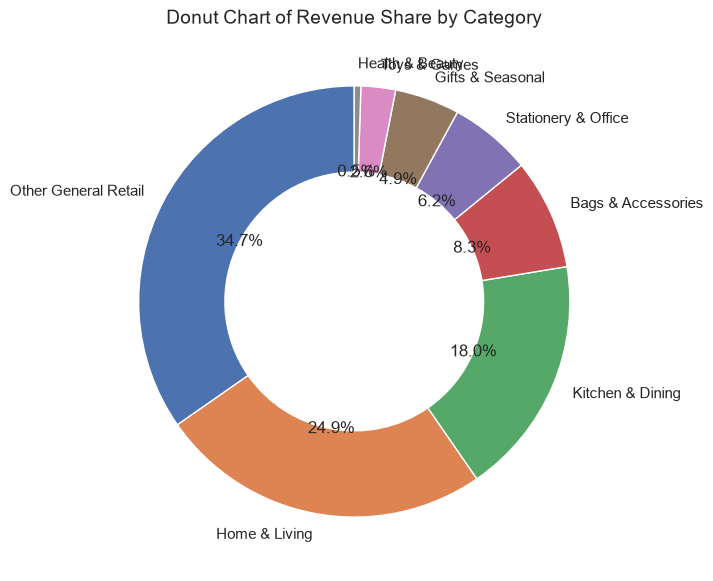

In [7]:
cat_rev = valid_sales.groupby('Product_Category')['Total_Amount'].sum().sort_values(ascending=False)

# Vertical Bar Chart of Category Revenue
plt.figure(figsize=(10, 5))
cat_rev.plot(kind='bar', color='steelblue')
plt.title('Vertical Bar Chart of Revenue by Product Category (DAV Practical 8 Style)', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=30, ha='right')
plt.show()

# Donut Chart of Revenue Share (DAV Practical 8 Style with wedgeprops)
plt.figure(figsize=(7, 7))
cat_rev.plot(kind='pie', autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=0.4))
plt.title('Donut Chart of Revenue Share by Category', fontsize=14)
plt.ylabel('')
plt.show()

## Section 4: Customer Locations Analytics (DAV Practical 7 & 8 Style)
Top revenue countries and interactive choropleth map.

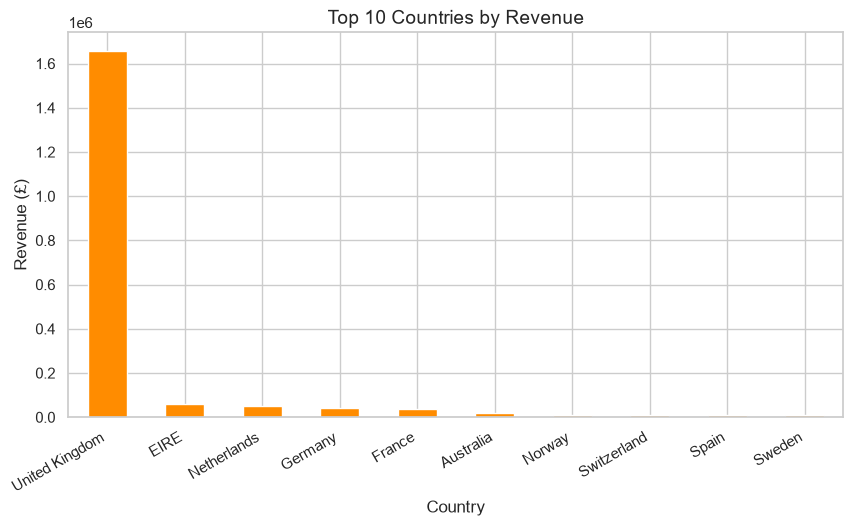

In [8]:
top_countries = valid_sales.groupby('Country')['Total_Amount'].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
top_countries.plot(kind='bar', color='darkorange')
plt.title('Top 10 Countries by Revenue', fontsize=14)
plt.xlabel('Country')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=30, ha='right')
plt.show()

# Interactive Plotly Choropleth Map
geo_df = valid_sales.groupby('Country')['Total_Amount'].sum().reset_index()
fig = px.choropleth(
    geo_df,
    locations='Country',
    locationmode='country names',
    color='Total_Amount',
    title='Global Revenue Choropleth Map (Plotly Express)',
    color_continuous_scale='Viridis'
)
fig.show()

## Section 5: Delivery Times and Fulfillment Performance
Box plots across countries and delivery status breakdown.

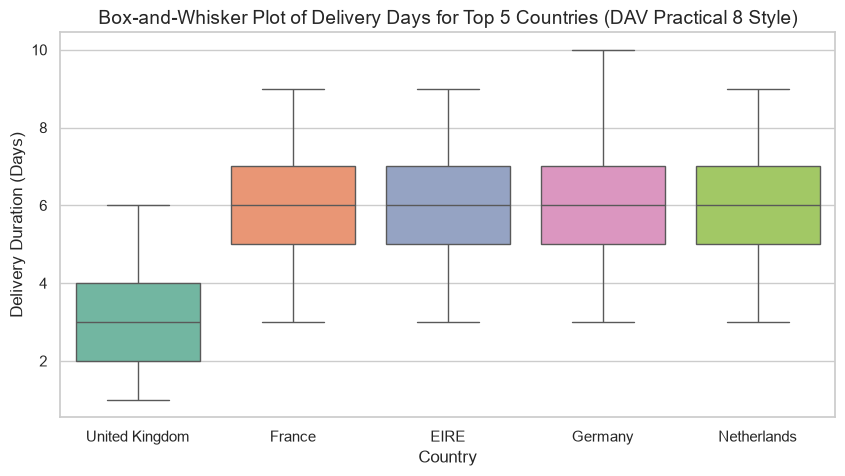

In [9]:
top5 = df['Country'].value_counts().head(5).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[(df['Country'].isin(top5)) & (~df['Is_Cancelled'])], x='Country', y='Delivery_Days', palette='Set2')
plt.title('Box-and-Whisker Plot of Delivery Days for Top 5 Countries (DAV Practical 8 Style)', fontsize=14)
plt.xlabel('Country')
plt.ylabel('Delivery Duration (Days)')
plt.show()

## Section 6: Customer Reviews and Satisfaction Analytics
Correlation between delivery speed and review scores.

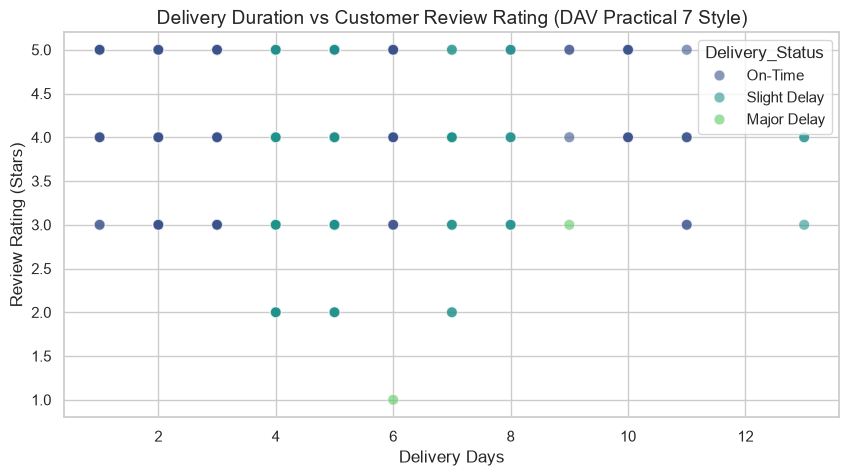

In [10]:
plt.figure(figsize=(10, 5))
sample_scatter = df[~df['Is_Cancelled']].sample(n=1000, random_state=42)
sns.scatterplot(
    data=sample_scatter,
    x='Delivery_Days',
    y='Review_Rating',
    hue='Delivery_Status',
    palette='viridis',
    alpha=0.6,
    s=60
)
plt.title('Delivery Duration vs Customer Review Rating (DAV Practical 7 Style)', fontsize=14)
plt.xlabel('Delivery Days')
plt.ylabel('Review Rating (Stars)')
plt.show()

## Section 7: Purchasing Trends and Temporal Patterns (DAV Practical 6 & 7 Style)
Peak shopping hours and day of week activity.

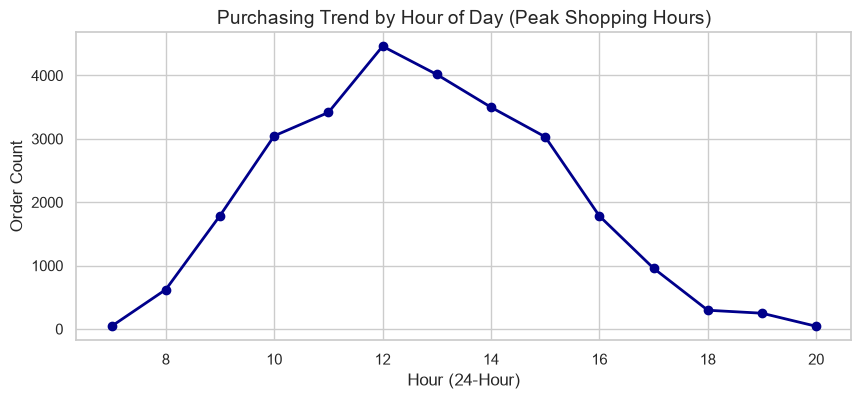

In [11]:
hourly = valid_sales.groupby('Hour')['Invoice'].nunique()
plt.figure(figsize=(10, 4))
plt.plot(hourly.index, hourly.values, marker='o', color='darkblue', linewidth=2)
plt.title('Purchasing Trend by Hour of Day (Peak Shopping Hours)', fontsize=14)
plt.xlabel('Hour (24-Hour)')
plt.ylabel('Order Count')
plt.grid(True)
plt.show()

## Section 8: Time Series Moving Averages and ARIMA Forecasting (DAV Practical 6 Style)
7-Day SMA, EMA, and ARIMA(1,1,1) forecasting.

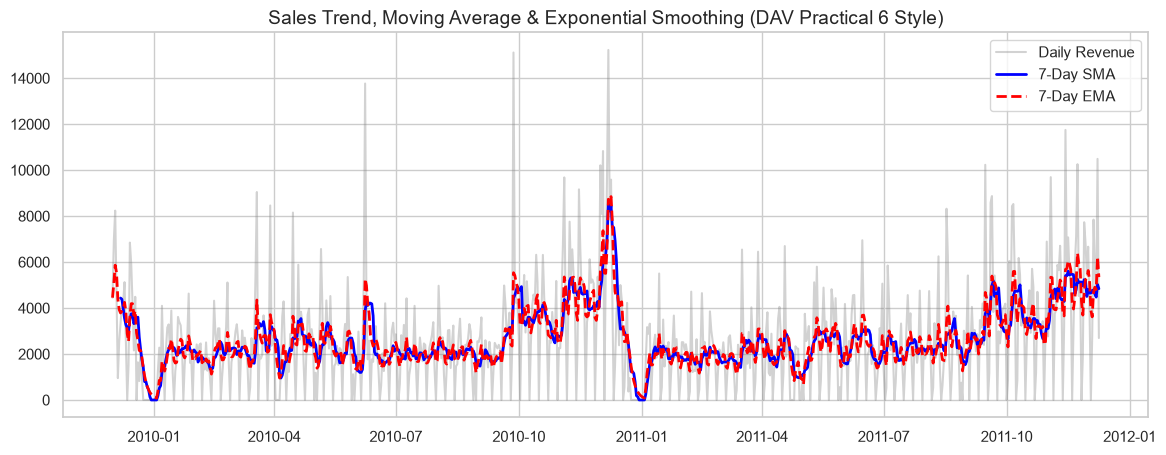

In [12]:
daily_sales = valid_sales.groupby('Date')['Total_Amount'].sum()
daily_sales.index = pd.to_datetime(daily_sales.index)
daily_sales = daily_sales.asfreq('D').fillna(0)

# 7-Day SMA and EMA (DAV Practical 6 style)
sma = daily_sales.rolling(window=7).mean()
ema = daily_sales.ewm(span=7, adjust=False).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales, label='Daily Revenue', alpha=0.35, color='gray')
plt.plot(sma, label='7-Day SMA', color='blue', linewidth=2)
plt.plot(ema, label='7-Day EMA', color='red', linestyle='--', linewidth=2)
plt.title('Sales Trend, Moving Average & Exponential Smoothing (DAV Practical 6 Style)', fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

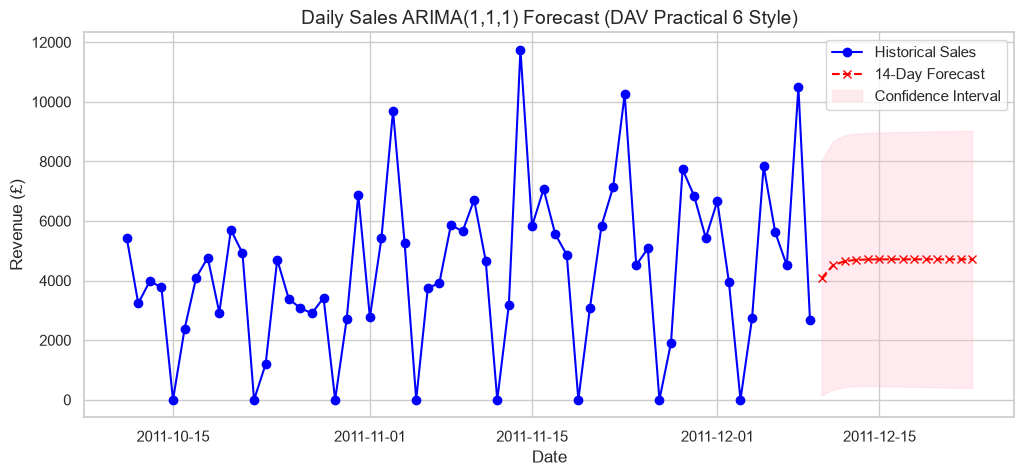

In [13]:
# ARIMA(1,1,1) 14-Day Forecast with Confidence Interval (DAV Practical 6 style)
model = ARIMA(daily_sales, order=(1, 1, 1))
results = model.fit()
forecast = results.get_forecast(steps=14)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.tail(60), marker='o', label='Historical Sales', color='blue')
plt.plot(forecast_mean, marker='x', color='red', linestyle='--', label='14-Day Forecast')
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='pink', alpha=0.3, label='Confidence Interval')
plt.title('Daily Sales ARIMA(1,1,1) Forecast (DAV Practical 6 Style)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.legend()
plt.grid(True)
plt.show()

## Section 9: Correlation Matrix and Linear Regression (DAV Practical 3 & 7 Style)
Correlation heatmap and linear regression modeling.

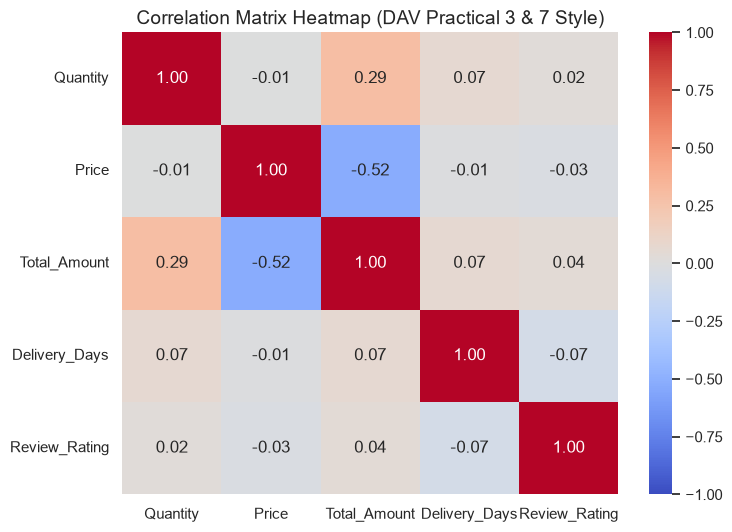

Mean Squared Error: 13687.81732180167
R2 Score: -0.3621756174095512


In [14]:
num_cols = ['Quantity', 'Price', 'Total_Amount', 'Delivery_Days', 'Review_Rating']
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Correlation Matrix Heatmap (DAV Practical 3 & 7 Style)', fontsize=14)
plt.show()

# Linear Regression Model
X = df[['Quantity', 'Price', 'Delivery_Days']].fillna(0)
y = df['Total_Amount'].fillna(0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg = LinearRegression()
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)
print('Mean Squared Error:', mean_squared_error(y_test, y_pred))
print('R2 Score:', r2_score(y_test, y_pred))

## Section 10: Interactive Grouped Bar Chart (DAV Practical 8 Style)
Interactive multi-metric visualization using Plotly Express.

In [15]:
cat_metrics = valid_sales.groupby('Product_Category').agg({
    'Quantity': 'mean',
    'Price': 'mean',
    'Review_Rating': 'mean'
}).reset_index()

fig = px.bar(
    cat_metrics,
    x='Product_Category',
    y=['Quantity', 'Price', 'Review_Rating'],
    barmode='group',
    title='Interactive Grouped Bar Chart of Category Metrics (DAV Practical 8 Style)',
    labels={'value': 'Average Value', 'variable': 'Metric'}
)
fig.show()